# 05 — Hata Yayilimi ve Olcum Duyarlilik Profili (Katman 4, G6)
Eklem noktasi konum hatasinin biyomekanik gostergelere etkisi esit degildir.
Kontrollu Gauss bozunumlari ile her olcume ozgu duyarlilik profili ve Hata Etki Haritasi cikarilir.

## Mimari Sozlesme ve Arastirma Ilkeleri

Bu notebook, **PhysioLoad AI — Olcum Duyarli Secici Biyomekanik Analiz Mimarisi**'nin bir parcasidir:
1. **Once olc, sonra guvenilirligini sinayarak raporla:** Her biyomekanik cikti bagimsiz degerlendirilir.
2. **Uc durumlu karar sozlesmesi:** `ACCEPTED` (Kabul), `REJECTED` (Ret), `NOT_COMPUTABLE` (Hesaplanamaz).
3. **Ayri dogrulama hatti:** Referans eklem verileri asla model tahminine girdi yapilmaz; yalnizca hata analizi ve A0-A4 karsilastirmasinda kullanilir.
4. **Veri sizintisini onleme:** Kisi ve deneme bazli boluntuleme (ayni katilimci train/val/test arasinda karismaz).
5. **Esik secimi:** Sayisal esikler yalnizca validation bolumunde belirlenir; test kumesi karsilastirma icin saklanir.


In [1]:
import sys
from pathlib import Path

# Proje kok dizini ve ortam kurulumu
here = Path.cwd().resolve()
code_root = next(p for p in (here, *here.parents) if (p / 'physioload_env.py').exists())
sys.path.insert(0, str(code_root))

from physioload_env import setup_environment
env = setup_environment(root=code_root)
print("Ortam Basariyla Yuklendi:")
print(env.summary())


Ortam Basariyla Yuklendi:
context       : vscode local
user          : berk-can
processed ver : v1
device        : cpu
code root     : C:\Users\Berk\Desktop\BİTİRME PROJESİ\physioload ai
artifacts root: C:\Users\Berk\Desktop\BİTİRME PROJESİ\physioload ai
data root     : C:\Users\Berk\Desktop\BİTİRME PROJESİ\physioload ai


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from physioload.geometry import joint_angle_degrees
from physioload.sensitivity import measurement_sensitivity_profile, error_impact_map

# Dirsek eklemi geometrisi (Omuz - Dirsek - Bilek)
elbow_points = {
    'shoulder': (150.0, 100.0),
    'elbow':    (200.0, 180.0),
    'wrist':    (280.0, 160.0),
}

# Dirsek acisi fonksiyonu
calc_elbow = lambda pts: joint_angle_degrees(pts['shoulder'], pts['elbow'], pts['wrist'])
base_angle = calc_elbow(elbow_points)
print(f"Temel Dirsek Acisi: {base_angle:.2f} derece")

# Kontrollu 2.5 piksellik konum bozunumu (Monte Carlo U_j gostergesi)
profile = measurement_sensitivity_profile(
    elbow_points, calc_elbow,
    sigma_px=2.5, samples=1000, quantile=0.95, seed=42
)
df_profile = pd.DataFrame([p.__dict__ for p in profile])
print("\nOlcum Duyarlilik Profili:")
print(df_profile)


Temel Dirsek Acisi: 107.97 derece

Olcum Duyarlilik Profili:
   landmark  mean_absolute_change  quantile_change  valid_samples
0     elbow              2.070615         5.262557           1000
1     wrist              1.430770         3.491726           1000
2  shoulder              1.171857         2.965449           1000


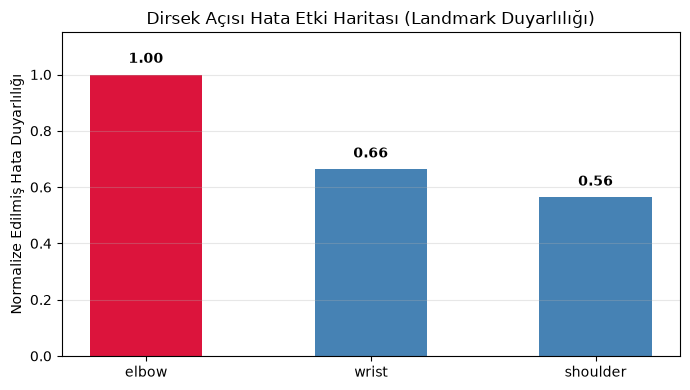

Biyomekanik Cikarim: Dirsek noktasindaki konum hatasi aciyi en cok degistiren ana kaynaktir.


In [3]:
# Hata Etki Haritasi (Normalize Etki) ve Gorsellestirme
impact = error_impact_map(profile)

plt.figure(figsize=(7, 4), dpi=100)
bars = plt.bar(impact.keys(), impact.values(), color=['crimson' if v == 1.0 else 'steelblue' for v in impact.values()], width=0.5)
plt.title('Dirsek Açısı Hata Etki Haritası (Landmark Duyarlılığı)')
plt.ylabel('Normalize Edilmiş Hata Duyarlılığı')
plt.ylim(0, 1.15)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.03, f"{yval:.2f}", ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("Biyomekanik Cikarim: Dirsek noktasindaki konum hatasi aciyi en cok degistiren ana kaynaktir.")
